# Lab 3 Pre-Lab: Neural Networks & Computer Vision Basics

You are NOT allowed to import any other libraries in this notebook otherwise points will be deducted. If you need to, please confirm with the TA.
`''' TODO '''` Indicates where your solution code should go. Please ensure code is readable easily.

For a further resource to the material covered in class, please check the following link. It is an introduction to constructing a simple neural network including ReLU and sigmoid activation functions, please read this tutorial before completing the prelab: [Deep Neural Network Step by Step](https://massivefile.com/Building_your_Deep_Neural_Network/).


## 1. Simple Neural Network

For this task, you'll implement a rudimentary neural network with one hidden layer.

**Network Architecture:**

- **Input Layer:**
   - 3 neurons
- **Hidden Layer:**
   - 6 neurons
   - Weight matrix `W1` and bias vector `b1`
   - Activation: ReLU
- **Output Layer:**
   - 4 neurons
   - Weight matrix `W2` and bias vector `b2`
   - Activation: Sigmoid

**Tasks:**

1. **Activation Function:**
   - Implement the ReLU and sigmoid activation functions manually, without using external libraries for this purpose.
      - The ReLU activation function is defined as:

          `ReLU(z) = max(0, z)`

      - The sigmoid activation function is defined as:

          `σ(z) = 1 / (1 + e^(−z))`


2. **Initialization:**
   - Create an input vector `X` with 3 random values between 0 and 1.
   - Based on the network architecture, initialize the weight matrices `W1` and `W2` with random values between 0 and 1.
   - Similarly, initialize the bias vectors `b1` and `b2` with random values between 0 and 1.

   You can use `np.random.rand()`

3. **Forward Pass:**
   - Using the initialized values and considering the specified network architecture, perform the forward pass through the network. Make sure to:
     - Compute the activations for the hidden layer.
     - Apply the ReLU activation function.
     - Compute the activations for the output layer.
     - Apply the sigmoid activation function to get the final output.

4. **Display the Result:**
   - Print the final output from the neural network.

**Note:**
Ensure the matrices' shapes are compatible throughout the network. Do not use external libraries for the forward pass. You are not allowed to import any other libraries.


In [6]:
import numpy as np
np.random.seed(42) # Do not modify

# Activation Functions
def relu(z):
    # Keep positive values and zero out negatives, i.e. max(0, z), element by element
    return z * (z > 0)

def sigmoid(z):
    # Squash every value into (0, 1) using 1 / (1 + e^(-z))
    return 1 / (1 + np.exp(-z))

# 1. Initialization
X = np.random.rand(3, 1)   # Input vector: 3 random values in [0, 1), shaped as a 3x1 column
W1 = np.random.rand(6, 3)  # Hidden-layer weights: 6 hidden neurons x 3 inputs
W2 = np.random.rand(4, 6)  # Output-layer weights: 4 output neurons x 6 hidden neurons
b1 = np.random.rand(6, 1)  # Hidden-layer biases: one per hidden neuron (6x1)
b2 = np.random.rand(4, 1)  # Output-layer biases: one per output neuron (4x1)

# 2. Forward Pass
Z1 = W1 @ X + b1  # Hidden pre-activation: (6x3)(3x1) + (6x1) -> 6x1
A1 = relu(Z1)     # Hidden activation: apply ReLU to every hidden value
Z2 = W2 @ A1 + b2 # Output pre-activation: (4x6)(6x1) + (4x1) -> 4x1
A2 = sigmoid(Z2)  # Final output: apply sigmoid to get 4 values between 0 and 1

# 3. Display the Result
print("Final Output A2:")
print(A2)


Final Output A2:
[[0.97339443]
 [0.97209919]
 [0.99846254]
 [0.96810729]]


## 3.3 Images
You can use the `imshow` function to show images. Here is an example:

/tmp/ipykernel_3761269/996636489.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread('cat.jpg')


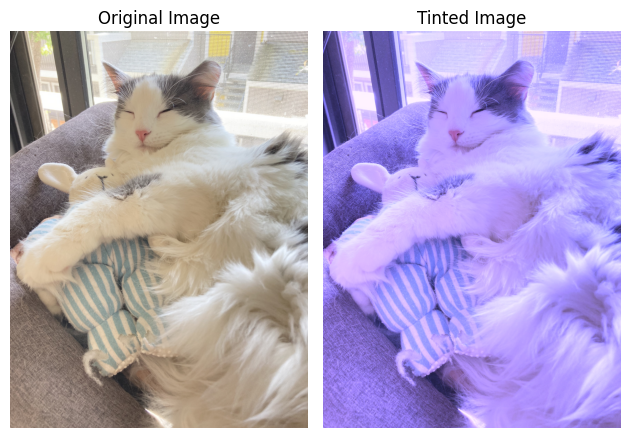

In [7]:
import numpy as np
import imageio
import matplotlib.pyplot as plt
from skimage.transform import resize

# Read an image from the 'assets' folder using imageio
img = imageio.imread('cat.jpg')
# Tint the image by scaling each color channel
img_tinted = img * [1, 0.95, 2]

# A slight gotcha with imshow is that it might give strange results
# if presented with data that is not uint8. To work around this, we
# explicitly cast the image to uint8 before displaying it.
img_tinted = np.clip(img_tinted, 0, 255).astype(np.uint8)

# Show the original image
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')  # Remove axes

# Show the tinted image
plt.subplot(1, 2, 2)
plt.imshow(img_tinted)
plt.title('Tinted Image')
plt.axis('off')  # Remove axes

# Display both images
plt.tight_layout()
plt.show()


## 2. Image Manipulations

You will be working with and manipulating either `messi.jpeg` or `cat.jpg` which is found in your repos.

**Tasks:**

1. **Image Display:**
   Load image`'messi.jpeg'` or `'cat.jpeg'` using PIL. Display the loaded image using matplotlib. You may find `open()` from PIL and `imshow()` from matplotlib useful.

2. **Image to Numpy Array:**
   Convert the image into a NumPy array and print its shape.

3. **Color Channels:**
   Split the image into its R, G, B channels and display each channel separately.

4. **Grayscale Conversion:**
   Convert the image to grayscale and display the grayscale image.

5. **Image Normalization:**
   Normalize the grayscale image such that values are in the range [0,1]. Print the minimum and maximum values before and after normalization.

6. **Image Crop:**
   Extract a center crop of 500x500 from the grayscale image and display the resized image.

7. **Convolution with Sobel Kernel:**
Manually apply convolution (do not use built-in functions like `numpy.convolve` or `scipy.signal.convolve2d`) to the cropped 500x500 image using the Sobel kernel provided below. Display the convoluted image.
   
   Sobel kernel:
   `[[-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]]`


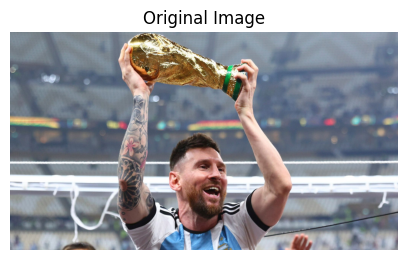

Image shape: (1152, 2048, 3)


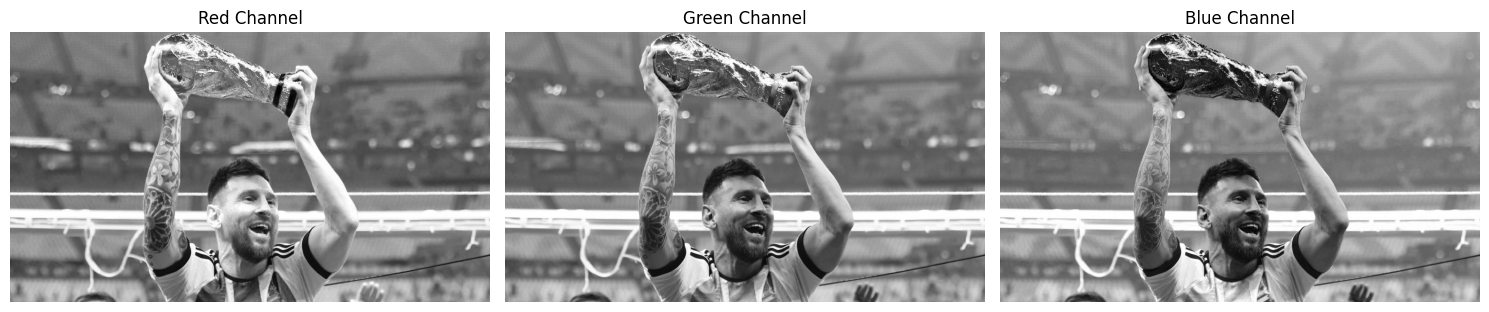

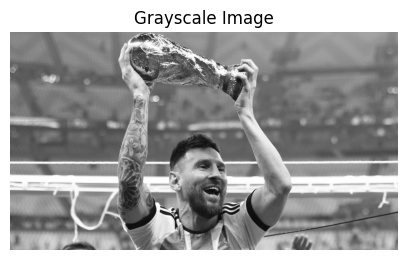

Before normalization - min: 0.0 max: 255.0
After normalization - min: 0.0 max: 1.0
Crop shape: (500, 500)


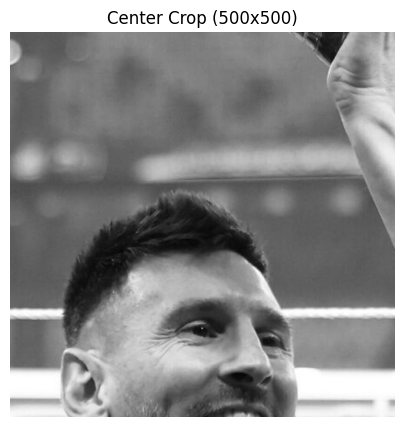

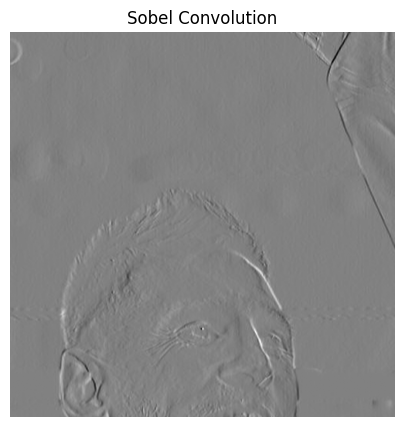

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# 1. Load the image using PIL & Display
img = Image.open('messi.jpeg').convert('RGB')  # Open the image and force 3-channel RGB (use 'cat.jpg' for the cat image)
plt.figure(figsize=(5, 5))                     # Create a figure of a reasonable size
plt.imshow(img)                                # Draw the loaded image
plt.title('Original Image')                    # Title the plot
plt.axis('off')                                # Hide the axis ticks
plt.show()                                     # Render the figure

# 2. Image to Numpy Array
img_arr = np.array(img)                        # Convert the PIL image to an array of shape (H, W, 3)
print("Image shape:", img_arr.shape)           # Print the array shape

# 3. Color Channels
R = img_arr[:, :, 0]                           # Red channel: every row and column, channel index 0
G = img_arr[:, :, 1]                           # Green channel: channel index 1
B = img_arr[:, :, 2]                           # Blue channel: channel index 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))  # One row with three side-by-side plots
for ax, ch, name in zip(axes, [R, G, B], ['Red', 'Green', 'Blue']):  # Pair each plot with its channel and name
    ax.imshow(ch, cmap='gray')                 # Show the channel as grayscale intensity
    ax.set_title(name + ' Channel')            # Title each plot with its channel name
    ax.axis('off')                             # Hide the axis ticks
plt.tight_layout()                             # Avoid overlapping titles
plt.show()                                     # Render the figure

# 4. Grayscale Conversion
gray = 0.299 * R + 0.587 * G + 0.114 * B       # Weighted sum of channels (standard luminance weights)
plt.figure(figsize=(5, 5))                     # Create a new figure
plt.imshow(gray, cmap='gray')                  # Show the grayscale image using a gray colormap
plt.title('Grayscale Image')                   # Title the plot
plt.axis('off')                                # Hide the axis ticks
plt.show()                                     # Render the figure

# 5. Image Normalization
print("Before normalization - min:", gray.min(), "max:", gray.max())  # Report the original value range
gray_norm = (gray - gray.min()) / (gray.max() - gray.min())           # Min-max scale values into [0, 1]
print("After normalization - min:", gray_norm.min(), "max:", gray_norm.max())  # Report the new value range

# 6. Image Center Crop
crop_size = 500                                # Side length of the square crop
h, w = gray_norm.shape                         # Height and width of the normalized grayscale image
top = (h - crop_size) // 2                     # Row where the centered crop starts
left = (w - crop_size) // 2                    # Column where the centered crop starts
crop = gray_norm[top:top + crop_size, left:left + crop_size]  # Slice out the 500x500 center region
print("Crop shape:", crop.shape)               # Confirm the crop is 500x500
plt.figure(figsize=(5, 5))                     # Create a new figure
plt.imshow(crop, cmap='gray')                  # Show the cropped image
plt.title('Center Crop (500x500)')             # Title the plot
plt.axis('off')                                # Hide the axis ticks
plt.show()                                     # Render the figure

# 7. Convolution with Sobel Kernel
sobel = np.array([[-1, 0, 1],
                  [-2, 0, 2],
                  [-1, 0, 1]])                 # Sobel kernel that responds to vertical edges
kernel = sobel[::-1, ::-1]                     # Flip the kernel in both directions (true convolution flips it)
k = kernel.shape[0]                            # Kernel size (3)
out_h = crop.shape[0] - k + 1                  # Output height with no padding (498)
out_w = crop.shape[1] - k + 1                  # Output width with no padding (498)
conv = np.zeros((out_h, out_w))                # Empty array to hold the convolution result
for i in range(out_h):                         # Slide the kernel down the rows
    for j in range(out_w):                     # Slide the kernel across the columns
        region = crop[i:i + k, j:j + k]        # Pick the 3x3 patch under the kernel
        conv[i, j] = np.sum(region * kernel)   # Multiply element-wise and sum to get one output pixel
plt.figure(figsize=(5, 5))                     # Create a new figure
plt.imshow(conv, cmap='gray')                  # Show the edge-filtered image
plt.title('Sobel Convolution')                 # Title the plot
plt.axis('off')                                # Hide the axis ticks
plt.show()                                     # Render the figure
